# 👄 Mouth State CNN — Hyperparameter Tuning (Synapse)

**الهدف:** نحسّن مودل الفم **v2** (98.59% accuracy، 98.75% recall للتثاؤب) بالبحث التلقائي عن أفضل hyperparameters.

**خطوات النوتبوك (نفس منهجية العين):**
1. **Hyperband search** بـ Keras Tuner على الـ train/val.
2. **إعادة تدريب** أفضل إعدادات بشكل كامل.
3. **Threshold tuning** على الـ val (لرفع recall التثاؤب).
4. **تقييم نهائي** على الـ test + مقارنة مع v2 و MobileNetV2.

> **التصليحات يلي نجحت بـ v2 ثابتة** (توحيد كل صورة لحالها، augmentation الإضاءة، BN momentum 0.9) — ما بنبحث فيها، بنبحث بس بالـ hyperparameters.

## 1) تجهيز البيئة

In [1]:
!pip install -q keras-tuner
import keras_tuner as kt

import os, sys, json, glob
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, precision_recall_fscore_support)
from mouth_dataset import make_mouth_dataset      # loader تبع Member 1

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات

In [2]:
OUT          = "/kaggle/working/mouth_cnn_tuned"
SPLITS_OUT   = "/kaggle/working/mouth_splits"
IMG_SIZE     = 96
BATCH        = 64
MAX_EPOCHS   = 15
FACTOR       = 3
FINAL_EPOCHS = 40
CLASS_NAMES  = ["no_yawn", "yawn"]
os.makedirs(OUT, exist_ok=True); os.makedirs(SPLITS_OUT, exist_ok=True)

## 3) الداتا

In [3]:
found = glob.glob("/kaggle/input/**/nitymed_out/labels/mouth_train.csv", recursive=True)
assert found, "ما لقيت داتا الفم! ضيفي output نوتبوك deep learning1 كـ Input (Add Input ← Your Work)."
ROOT = os.path.dirname(os.path.dirname(found[0]))
print("📂 الداتا موجودة بـ:", ROOT)

OLD_ROOT = "/kaggle/working/nitymed_out"
dfs = {}
for s in ["train", "val", "test"]:
    d = pd.read_csv(f"{ROOT}/labels/mouth_{s}.csv")
    d["path"] = d["path"].str.replace(OLD_ROOT, ROOT, regex=False)
    if s == "train":
        d = d.sample(frac=1, random_state=42).reset_index(drop=True)   # خلط كامل
    d.to_csv(f"{SPLITS_OUT}/mouth_{s}.csv", index=False)
    dfs[s] = d
    c = d.label.value_counts().sort_index()
    print(f"{s:5s}: {len(d):5d} images | videos={d.video.nunique():3d} | no_yawn={c.get(0,0)} yawn={c.get(1,0)}")

missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"مسارات الصور غلط! مثال: {missing[0]}"

train_ds = make_mouth_dataset(f"{SPLITS_OUT}/mouth_train.csv", training=True,  batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_mouth_dataset(f"{SPLITS_OUT}/mouth_val.csv",   training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_mouth_dataset(f"{SPLITS_OUT}/mouth_test.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)
print("✅ الداتا جاهزة")

📂 الداتا موجودة بـ: /kaggle/input/notebooks/halasaadabushendi/deep-learning1/nitymed_out
train:  5398 images | videos= 60 | no_yawn=2700 yawn=2698
val  :  1010 images | videos= 13 | no_yawn=455 yawn=555
test :  1276 images | videos= 14 | no_yawn=636 yawn=640
✅ الداتا جاهزة


## 4) فضاء البحث (Search Space)
| Hyperparameter | قيمة v2 | المدى يلي بنجربه |
|---|---|---|
| `base_filters` | 32 | 16، 32، 48 |
| `conv_dropout` | 0.20–0.30 | 0.1 → 0.4 |
| `dense_units` | 128 | 64، 128، 256 |
| `dense_dropout` | 0.5 | 0.3 → 0.6 |
| `l2` | 1e-4 | 1e-5، 1e-4، 1e-3 |
| `lr` | 1e-3 | 1e-4 → 3e-3 (log) |

**الهدف:** أقل `val_loss`. ⚠️ **الـ test ما بنلمسه أثناء البحث.**

In [4]:
METRICS = ["accuracy", keras.metrics.Precision(name="precision"),
           keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]

def build_model(hp):
    f      = hp.Choice("base_filters", [16, 32, 48])
    drop_c = hp.Float("conv_dropout", 0.1, 0.4, step=0.05)
    units  = hp.Choice("dense_units", [64, 128, 256])
    drop_d = hp.Float("dense_dropout", 0.3, 0.6, step=0.1)
    l2     = hp.Choice("l2", [1e-5, 1e-4, 1e-3])
    lr     = hp.Float("lr", 1e-4, 3e-3, sampling="log")

    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="mouth_rgb")
    x = layers.RandomFlip("horizontal")(inp)
    x = layers.RandomBrightness(0.3, value_range=(0.0, 1.0))(x)
    x = layers.RandomContrast(0.4)(x)
    x = layers.LayerNormalization(axis=[1, 2, 3], center=False, scale=False,
                                  epsilon=1e-3, name="per_image_standardization")(x)
    for mult in (1, 2, 4):
        for _ in range(2):
            x = layers.Conv2D(f * mult, 3, padding="same", use_bias=False,
                              kernel_regularizer=regularizers.l2(l2))(x)
            x = layers.BatchNormalization(momentum=0.9)(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop_c)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(drop_d)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_yawn")(x)
    model = keras.Model(inp, out, name="mouth_cnn_tuned")
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS)
    return model

## 5) البحث بـ Hyperband
⏱️ داتا الفم صغيرة، فالبحث أسرع بكثير من العين (تقريباً 20–30 دقيقة على GPU).

In [5]:
tuner = kt.Hyperband(build_model, objective=kt.Objective("val_loss", direction="min"),
                     max_epochs=MAX_EPOCHS, factor=FACTOR, seed=42,
                     directory="/kaggle/working/tuner", project_name="mouth_cnn", overwrite=True)
tuner.search_space_summary()
tuner.search(train_ds, validation_data=val_ds,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3)], verbose=2)

Trial 30 Complete [00h 01m 26s]
val_loss: 0.13852740824222565

Best val_loss So Far: 0.064708411693573
Total elapsed time: 00h 25m 24s


## 6) نتائج البحث (أفضل 10 تجارب)

In [6]:
HP_KEYS = ["base_filters", "conv_dropout", "dense_units", "dense_dropout", "l2", "lr"]
rows = []
for t in tuner.oracle.get_best_trials(num_trials=10):
    r = {k: t.hyperparameters.values[k] for k in HP_KEYS}
    r["val_loss"] = t.score
    rows.append(r)
trials = pd.DataFrame(rows)
trials.to_csv(f"{OUT}/top_trials.csv", index=False)
display(trials)
best_hp = tuner.get_best_hyperparameters(1)[0]
best_values = {k: best_hp.values[k] for k in HP_KEYS}
print("🏆 أفضل إعدادات:", json.dumps(best_values, indent=2))

,base_filters,conv_dropout,dense_units,dense_dropout,l2,lr,val_loss
0,32,0.15,128,0.4,0.00001,0.000722,0.064708
1,48,0.15,64,0.4,0.00001,0.000541,0.065394
2,32,0.30,256,0.4,0.00001,0.000583,0.072461
3,48,0.15,64,0.4,0.00001,0.000541,0.073976
4,32,0.15,128,0.4,0.00001,0.000722,0.081294
5,16,0.10,256,0.4,0.00010,0.002182,0.087736
6,16,0.25,64,0.3,0.00001,0.000218,0.088476
7,32,0.15,128,0.4,0.00001,0.000722,0.089349
8,16,0.15,256,0.4,0.00010,0.001515,0.094543
9,48,0.30,256,0.5,0.00001,0.000721,0.101501


🏆 أفضل إعدادات: {
  "base_filters": 32,
  "conv_dropout": 0.15000000000000002,
  "dense_units": 128,
  "dense_dropout": 0.4,
  "l2": 1e-05,
  "lr": 0.00072182541156161
}


## 7) إعادة تدريب أفضل إعدادات بشكل كامل

Epoch 1/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 27s 187ms/step - accuracy: 0.8888 - auc: 0.9664 - loss: 0.2625 - precision: 0.9086 - recall: 0.8921 - val_accuracy: 0.9584 - val_auc: 0.9913 - val_loss: 0.1249 - val_precision: 0.9672 - val_recall: 0.9568 - learning_rate: 7.2183e-04
Epoch 2/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.9631 - auc: 0.9928 - loss: 0.1071 - precision: 0.9675 - recall: 0.9585 - val_accuracy: 0.9406 - val_auc: 0.9973 - val_loss: 0.1466 - val_precision: 0.9960 - val_recall: 0.8955 - learning_rate: 7.2183e-04
Epoch 3/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.9657 - auc: 0.9934 - loss: 0.1016 - precision: 0.9708 - recall: 0.9603 - val_accuracy: 0.9713 - val_auc: 0.9924 - val_loss: 0.1018 - val_precision: 0.9663 - val_recall: 0.9820 - learning_rate: 7.2183e-04
Epoch 4/40
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.9750 - auc: 0.9969 - loss: 0.0701 - precision: 0.9784 - recall: 0.9715 - val_accuracy: 0.9307 - val_auc: 0.9891 - val_loss: 0.

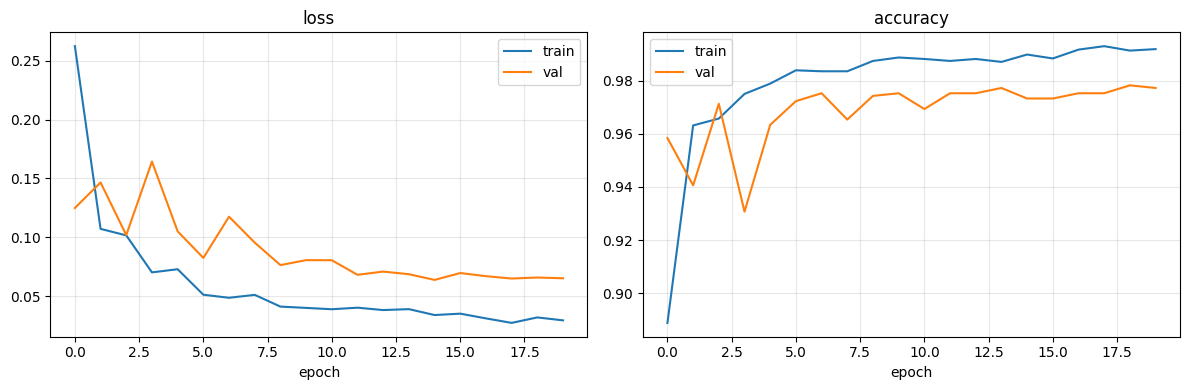

In [7]:
tf.keras.utils.set_random_seed(42)
model = tuner.hypermodel.build(best_hp)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(f"{OUT}/best.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(f"{OUT}/history.csv"),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=FINAL_EPOCHS, callbacks=callbacks)

h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8) Threshold Tuning (على الـ val)
النموذج بيطلع `p_yawn`. افتراضياً: `p_yawn ≥ 0.5` ← تثاؤب.
**تنزيل** الـ threshold (مثلاً 0.3) ← بنكشف تثاؤبات أكثر (recall أعلى) مقابل إنذارات خاطئة أكثر.
بنختار الـ threshold يلي بيعطي أعلى **F2-score لفئة yawn** على الـ **val** (F2 بتعطي الـ recall وزن أكبر).

In [8]:
y_val      = dfs["val"].label.values
p_yawn_val = model.predict(val_ds, verbose=0).ravel()

def yawn_scores(y, p, t):
    pred = (p >= t).astype(int)
    pr, rc, _, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
    f2 = 5 * pr[0] * rc[0] / (4 * pr[0] + rc[0] + 1e-9)
    return pr[0], rc[0], f2, (pred == y).mean()

ths = np.round(np.arange(0.10, 0.71, 0.05), 2)
sweep = pd.DataFrame([dict(zip(["threshold", "yawn_precision", "yawn_recall", "yawn_F2", "accuracy"],
                               (t, *yawn_scores(y_val, p_yawn_val, t)))) for t in ths])
BEST_T = float(sweep.loc[sweep.yawn_F2.idxmax(), "threshold"])
sweep.to_csv(f"{OUT}/threshold_sweep_val.csv", index=False)
display(sweep.style.format("{:.4f}").highlight_max(subset=["yawn_F2"]))
print(f"🎯 الـ threshold المختار (من الـ val): {BEST_T}")

,threshold,yawn_precision,yawn_recall,yawn_F2,accuracy
0,0.1000,0.9634,0.9964,0.9896,0.9772
1,0.1500,0.9701,0.9946,0.9896,0.9802
2,0.2000,0.9701,0.9928,0.9882,0.9792
3,0.2500,0.9700,0.9910,0.9867,0.9782
4,0.3000,0.9716,0.9874,0.9842,0.9772
5,0.3500,0.9733,0.9838,0.9817,0.9762
6,0.4000,0.9750,0.9838,0.9820,0.9772
7,0.4500,0.9749,0.9784,0.9777,0.9743
8,0.5000,0.9748,0.9766,0.9762,0.9733
9,0.5500,0.9748,0.9766,0.9762,0.9733


🎯 الـ threshold المختار (من الـ val): 0.1


## 9) التقييم النهائي على الـ Test Set
بالـ threshold الافتراضي (0.5) للمقارنة العادلة، وبالـ threshold المختار.

Test AUC (sklearn): 0.9993

              precision    recall  f1-score   support

     no_yawn     0.9858    0.9827    0.9843       636
        yawn     0.9829    0.9859    0.9844       640

    accuracy                         0.9843      1276
   macro avg     0.9843    0.9843    0.9843      1276
weighted avg     0.9843    0.9843    0.9843      1276



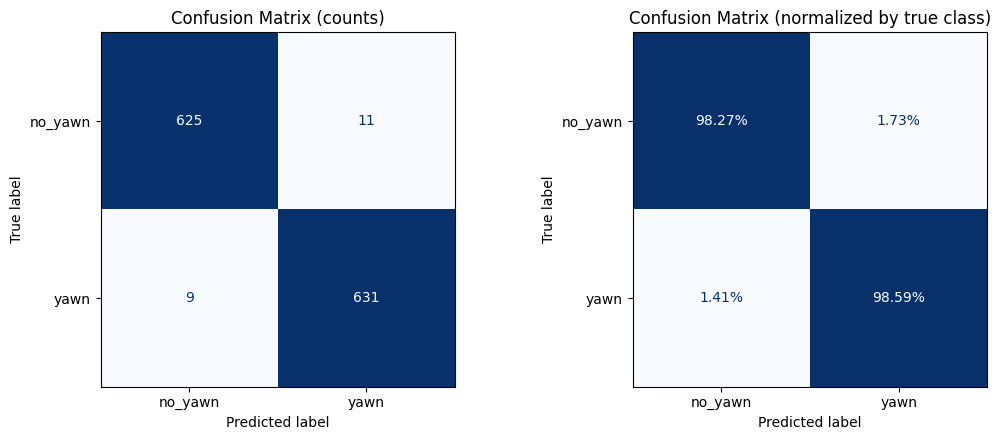

threshold=0.1: accuracy=0.9812 | yawn recall=0.9984 | CM=[[613, 23], [1, 639]]
threshold=0.5: accuracy=0.9843 | yawn recall=0.9859 | CM=[[625, 11], [9, 631]]


In [9]:
y_true = dfs["test"].label.values
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test AUC (sklearn): {roc_auc_score(y_true, y_prob):.4f}"); print()
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion Matrix (normalized by true class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

results = {}
for t in sorted({0.5, BEST_T}):
    yp = (y_prob >= t).astype(int)
    rep = classification_report(y_true, yp, target_names=CLASS_NAMES, digits=4, output_dict=True)
    results[str(t)] = {"accuracy": rep["accuracy"],
                       "yawn": {k: rep["yawn"][k] for k in ["precision", "recall", "f1-score"]},
                       "confusion_matrix": confusion_matrix(y_true, yp).tolist()}
    print(f"threshold={t}: accuracy={rep['accuracy']:.4f} | yawn recall={rep['yawn']['recall']:.4f} | CM={results[str(t)]['confusion_matrix']}")

## 10) حفظ النموذج والنتائج

In [10]:
model.save(f"{OUT}/mouth_cnn_tuned.keras")
model.save_weights(f"{OUT}/mouth_cnn_tuned.weights.h5")
metrics = {
    "model": "mouth_cnn_tuned",
    "params": int(model.count_params()),
    "epochs_trained": len(h),
    "best_val_loss": float(h.val_loss.min()),
    "test_accuracy": report["accuracy"],
    "test_auc": float(roc_auc_score(y_true, y_prob)),
    "no_yawn": {k: report["no_yawn"][k] for k in ["precision", "recall", "f1-score", "support"]},
    "yawn":    {k: report["yawn"][k]    for k in ["precision", "recall", "f1-score", "support"]},
    "confusion_matrix": cm.tolist(),
    "chosen_threshold": BEST_T,
    "at_chosen_threshold": results[str(BEST_T)],
    "best_hyperparameters": best_values,
    "search": {"algorithm": "Hyperband", "max_epochs": MAX_EPOCHS, "factor": FACTOR,
               "objective": "val_loss", "trials": len(tuner.oracle.trials)},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "mouth_cnn_tuned",
  "params": 304993,
  "epochs_trained": 20,
  "best_val_loss": 0.06374026089906693,
  "test_accuracy": 0.9843260188087775,
  "test_auc": 0.9992727987421384,
  "no_yawn": {
    "precision": 0.9858044164037855,
    "recall": 0.9827044025157232,
    "f1-score": 0.984251968503937,
    "support": 636.0
  },
  "yawn": {
    "precision": 0.9828660436137072,
    "recall": 0.9859375,
    "f1-score": 0.984399375975039,
    "support": 640.0
  },
  "confusion_matrix": [
    [
      625,
      11
    ],
    [
      9,
      631
    ]
  ],
  "chosen_threshold": 0.1,
  "at_chosen_threshold": {
    "accuracy": 0.9811912225705329,
    "yawn": {
      "precision": 0.9652567975830816,
      "recall": 0.9984375,
      "f1-score": 0.9815668202764977
    },
    "confusion_matrix": [
      [
        613,
        23
      ],
      [
        1,
        639
      ]
    ]
  },
  "best_hyperparameters": {
    "base_filters": 32,
    "conv_dropout": 0.15000000000000002,
    "dense_u

## 11) مقارنة مع v2 و MobileNetV2
**اختياري:** ضيفي output نوتبوكات `mouth-CNN-v2` و `mouth-mobilenet-training` كـ Input.

In [11]:
rows = []
for name in ["mouth_cnn_v2", "mouth_mobilenetv2", "mouth_cnn_tuned"]:
    f = glob.glob(f"/kaggle/input/**/{name}/metrics.json", recursive=True)
    if name == "mouth_cnn_tuned":
        m = metrics
    elif f:
        m = json.load(open(f[0]))
    else:
        continue
    rows.append({"model": m["model"], "params": m["params"], "val_loss": m["best_val_loss"],
                 "accuracy": m["test_accuracy"], "auc": m["test_auc"],
                 "yawn_recall": m["yawn"]["recall"], "yawn_precision": m["yawn"]["precision"],
                 "missed_yawns": m["confusion_matrix"][1][0], "false_alarms": m["confusion_matrix"][0][1]})
cmp = pd.DataFrame(rows).set_index("model")
cmp.to_csv(f"{OUT}/comparison.csv")
display(cmp)
if len(cmp) == 1:
    print("ℹ️ لمقارنة كاملة: ضيفي output نوتبوكات mouth-CNN-v2 (والـ mobilenet) كـ Input.")

,params,val_loss,accuracy,auc,yawn_recall,yawn_precision,missed_yawns,false_alarms
model,,,,,,,,
mouth_cnn_v2,304993,0.096972,0.985893,0.999285,0.987500,0.984424,8,10
mouth_cnn_tuned,304993,0.063740,0.984326,0.999273,0.985938,0.982866,9,11
